In [99]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
import warnings
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings('ignore')

https://www.kdnuggets.com/2023/08/leveraging-xgboost-timeseries-forecasting.html
xgb.plot_importance(reg)

In [101]:
path = r"C:\Users\sophi\Desktop\vie de la donnée M2\TP XGBoost\cleaned_data.csv"
data = pd.read_csv(path, sep = ',')
data.head()

,date,temperature_om,humidity_om,pressure_om,wind_speed_om,wind_direction_om,precipitation_om,soil_temperature_6cm_om,soil_temperature_18cm_om,soil_temperature_54cm_om,...,temp_74cm_imputed,air_temperature_imputed,humi_6cm_imputed,humi_18cm_imputed,humi_54cm_imputed,humi_74cm_imputed,pH_6cm_imputed,pH_18cm_imputed,pH_54cm_imputed,pH_74cm_imputed
0,2025-09-29 08:00:00,11.580501,86.0,1023.599976,5.506941,348.690094,0.0,10.980500,12.680500,14.9305,...,0,0,0,0,0,0,0,0,0,0
1,2025-09-29 09:00:00,13.980500,79.0,1023.700012,8.427383,19.983198,0.0,12.980500,12.680500,14.9305,...,0,0,0,0,0,0,0,0,0,0
2,2025-09-29 10:00:00,15.880500,75.0,1023.299988,10.086427,34.824570,0.0,15.130500,12.830501,14.8805,...,0,0,0,0,0,0,0,0,0,0
3,2025-09-29 11:00:00,17.280499,69.0,1023.000000,11.720751,42.510403,0.0,17.030499,13.180500,14.8805,...,0,0,0,0,0,0,0,0,0,0
4,2025-09-29 12:00:00,18.130499,61.0,1022.799988,12.096214,53.471054,0.0,18.030499,13.580501,14.8805,...,0,0,0,0,0,0,0,0,0,0


In [103]:
station = ['humidity', 'air_temperature', 'precipitation', 'temp_6cm', 'humi_6cm', 'pH_6cm','temp_18cm', 'humi_18cm', 'pH_18cm', 'temp_54cm', 'humi_54cm', 'pH_54cm', 'temp_74cm', 'humi_74cm', 'pH_74cm'] 
data_station = renamed_data[station]
data_station.head()

,humidity,air_temperature,precipitation,temp_6cm,humi_6cm,pH_6cm,temp_18cm,humi_18cm,pH_18cm,temp_54cm,humi_54cm,pH_54cm,temp_74cm,humi_74cm,pH_74cm
date,,,,,,,,,,,,,,,
2025-09-29 08:00:00,79.5,15.0,0.0,13.10,14.06,6.40,13.40,18.80,6.81,14.00,17.11,8.50,13.13,16.94,6.30
2025-09-29 09:00:00,75.3,17.3,0.0,13.27,14.09,6.30,13.55,18.80,6.97,14.04,17.18,8.32,13.62,17.00,6.42
2025-09-29 10:00:00,68.8,19.3,0.0,13.76,14.17,6.33,13.97,18.93,7.01,14.20,17.26,8.19,14.68,17.16,6.44
2025-09-29 11:00:00,65.7,20.1,0.0,14.71,14.50,6.44,15.14,19.11,6.90,14.78,17.41,8.27,16.67,17.38,6.38
2025-09-29 12:00:00,66.0,19.0,0.0,15.98,14.37,6.41,16.70,19.18,7.14,15.76,17.50,8.43,18.34,17.30,6.49


In [105]:
# Définir la cible = température du sol à 74 cm
target = "temp_74cm"
features = [col for col in data_station.columns if col not in [target, 'humidity', 'precipitation']]

In [107]:
X = data_station[features]
y = data_station[target]
# =============================
# 2. Entraîner le modèle
# =============================
lags = [1,2,3,4,5,6,7]   # adapter selon fréquence et horizon

for col in station:
    for lag in lags:
        data_station[f"{col}_lag{lag}"] = data_station[col].shift(lag)
# code des lags/rolling ci-dessus...
windows = [3,6,12,24]
for col in station:
    for w in windows:
        data_station[f"{col}_roll_mean_{w}"] = data_station[col].shift(1).rolling(w).mean()
        data_station[f"{col}_roll_std_{w}"]  = data_station[col].shift(1).rolling(w).std()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.5,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)

model.fit(X_train, y_train)



,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [110]:
# =============================================================================
# Evaluation du modèle
# =============================================================================
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prédictions sur le jeu de test
y_pred_test = model.predict(X_test)

# Calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae = mean_absolute_error(y_test, y_pred_test)
r2 = r2_score(y_test, y_pred_test)

# Affichage des résultats
print("\n📊 Évaluation du modèle sur le jeu de test :")
print(f" - RMSE : {rmse:.2f}")
print(f" - MAE  : {mae:.2f}")
print(f" - R²   : {r2:.3f}")


📊 Évaluation du modèle sur le jeu de test :
 - RMSE : 0.38
 - MAE  : 0.29
 - R²   : 0.979


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

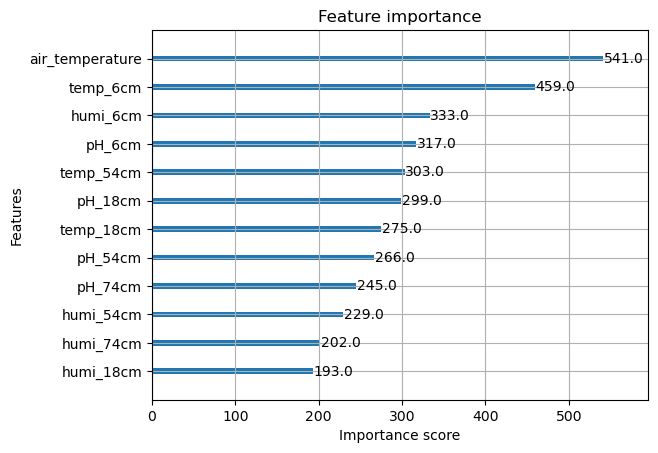

In [112]:
xgb.plot_importance(model)

In [114]:
X = data_station[features]
y = data_station[target]
# =============================
# 2. Entraîner le modèle
# =============================
lags = [1,2,3,4,5,6,7]   # adapter selon fréquence et horizon

for col in station:
    for lag in lags:
        data_station[f"{col}_lag{lag}"] = data_station[col].shift(lag)
# code des lags/rolling ci-dessus...
windows = [3,6,12,24]
for col in station:
    for w in windows:
        data_station[f"{col}_roll_mean_{w}"] = data_station[col].shift(1).rolling(w).mean()
        data_station[f"{col}_roll_std_{w}"]  = data_station[col].shift(1).rolling(w).std()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.5,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)

model.fit(X_train, y_train)



,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [116]:
# =============================================================================
# Evaluation du modèle
# =============================================================================
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prédictions sur le jeu de test
y_pred_test = model.predict(X_test)

# Calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae = mean_absolute_error(y_test, y_pred_test)
r2 = r2_score(y_test, y_pred_test)

# Affichage des résultats
print("\n📊 Évaluation du modèle sur le jeu de test :")
print(f" - RMSE : {rmse:.2f}")
print(f" - MAE  : {mae:.2f}")
print(f" - R²   : {r2:.3f}")


📊 Évaluation du modèle sur le jeu de test :
 - RMSE : 0.33
 - MAE  : 0.26
 - R²   : 0.981


In [120]:
X = data_station[features]
y = data_station[target]
# =============================
# 2. Entraîner le modèle
# =============================
lags = [1,2,3,4,5,6,7]   # adapter selon fréquence et horizon

for col in station:
    for lag in lags:
        data_station[f"{col}_lag{lag}"] = data_station[col].shift(lag)
# code des lags/rolling ci-dessus...
windows = [3,6,12,24]
for col in station:
    for w in windows:
        data_station[f"{col}_roll_mean_{w}"] = data_station[col].shift(1).rolling(w).mean()
        data_station[f"{col}_roll_std_{w}"]  = data_station[col].shift(1).rolling(w).std()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)

model.fit(X_train, y_train)



,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [122]:
# =============================================================================
# Evaluation du modèle
# =============================================================================
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prédictions sur le jeu de test
y_pred_test = model.predict(X_test)

# Calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae = mean_absolute_error(y_test, y_pred_test)
r2 = r2_score(y_test, y_pred_test)

# Affichage des résultats
print("\n📊 Évaluation du modèle sur le jeu de test :")
print(f" - RMSE : {rmse:.2f}")
print(f" - MAE  : {mae:.2f}")
print(f" - R²   : {r2:.3f}")


📊 Évaluation du modèle sur le jeu de test :
 - RMSE : 0.29
 - MAE  : 0.21
 - R²   : 0.988


In [142]:
def create_time_feature_from_index(df):
    # On utilise df.index au lieu de df['date']
    df['dayofmonth'] = df.index.day
    df['dayofweek'] = df.index.dayofweek
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.dayofyear
    df['weekofyear'] = df.index.isocalendar().week # ou .week pour les anciennes versions
    return df

In [138]:
def create_time_feature(df):
    df['dayofmonth'] = df['date'].dt.day
    df['dayofweek'] = df['date'].dt.dayofweek
    df['quarter'] = df['date'].dt.quarter
    df['month'] = df['date'].dt.month
    df['year'] = df['date'].dt.year
    df['dayofyear'] = df['date'].dt.dayofyear
    df['weekofyear'] = df['date'].dt.weekofyear
    return df

In [144]:
create_time_feature(data_station)
data_station.head()

KeyError: 'date'